In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Professional styling for charts
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

# Load the clean data from preprocessing
df = pd.read_csv("../data/processed/superstore_clean.csv")
df['Order_Date'] = pd.to_datetime(df['Order_Date']) # Ensure it's datetime

print(f"Loaded {len(df)} clean records.")

Loaded 9800 clean records.


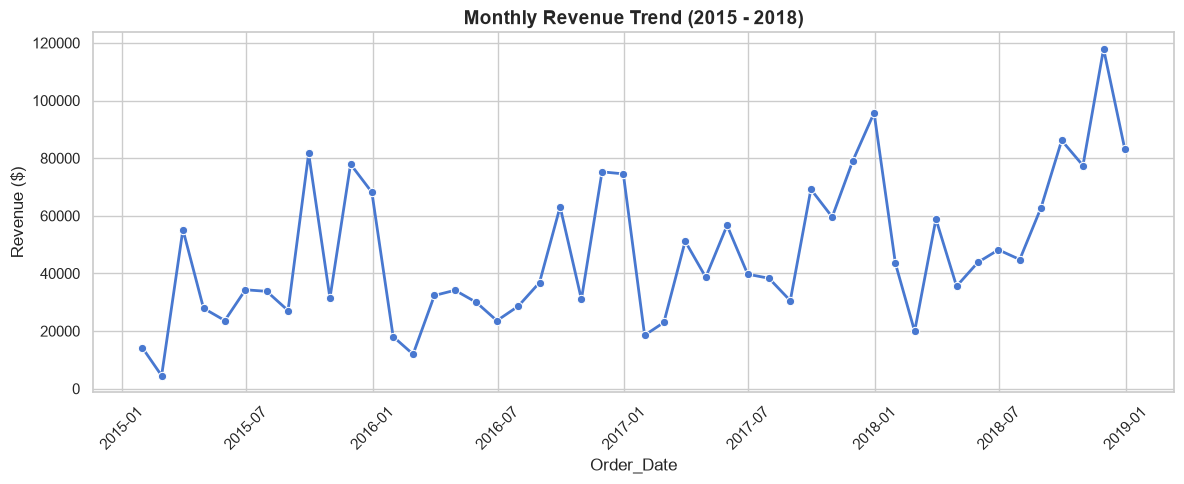

In [12]:
monthly = df.set_index("Order_Date").resample("ME")["Revenue"].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="Order_Date", y="Revenue", marker="o", linewidth=2)
plt.title("Monthly Revenue Trend (2015 - 2018)", fontsize=14, fontweight="bold")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

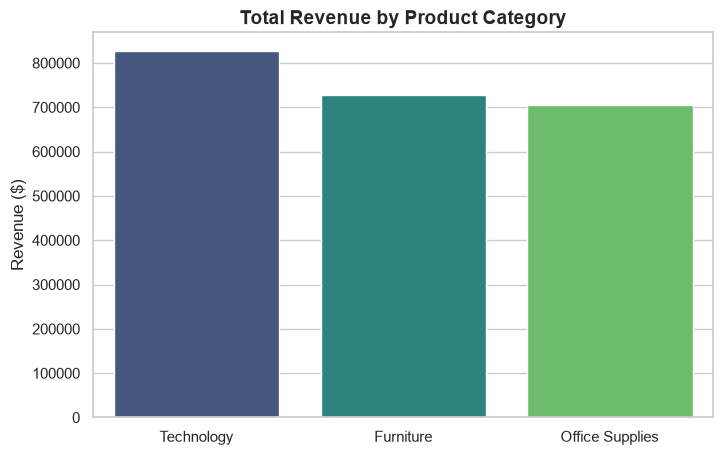

In [13]:
cat_rev = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=cat_rev,   x="Category",     y="Revenue", hue="Category",     palette="viridis", legend=False)
plt.title('Total Revenue by Product Category', fontsize=14, fontweight='bold')
plt.ylabel('Revenue ($)')
plt.xlabel('')
plt.show()

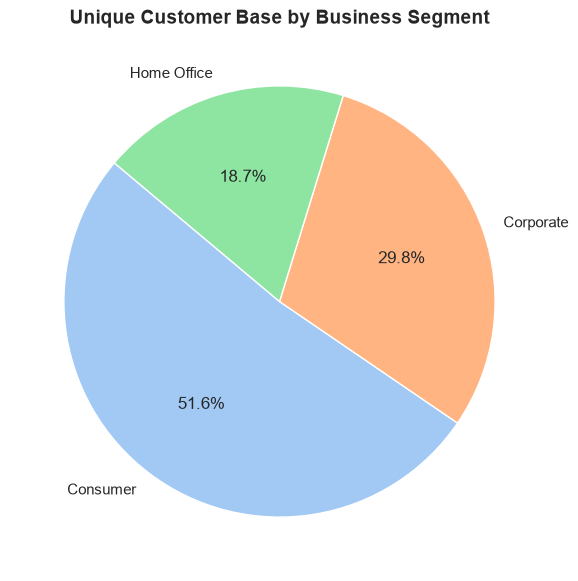

In [14]:
seg_counts = df.groupby('Customer_ID')['Segment'].first().value_counts()

plt.figure(figsize=(7, 7))
plt.pie(seg_counts, labels=seg_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("pastel"))
plt.title('Unique Customer Base by Business Segment', fontsize=14, fontweight='bold')
plt.show()

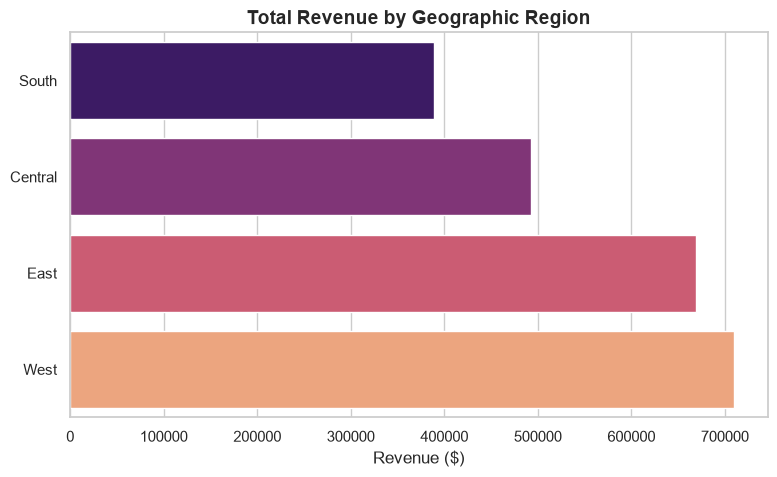

In [15]:
reg_rev = df.groupby('Region')['Revenue'].sum().sort_values(ascending=True).reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(data=reg_rev,   x="Revenue",      y="Region",  hue="Region",       palette="magma",   legend=False)
plt.title('Total Revenue by Geographic Region', fontsize=14, fontweight='bold')
plt.xlabel('Revenue ($)')
plt.ylabel('')
plt.show()

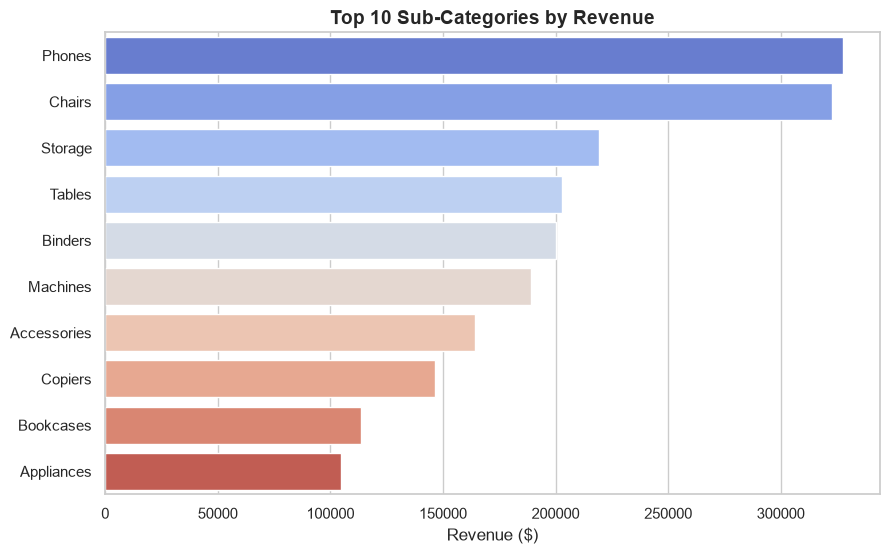

In [16]:
subcat_rev = df.groupby('Sub-Category')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=subcat_rev,x="Revenue", y="Sub-Category", hue="Sub-Category", palette="coolwarm",legend=False)
plt.title('Top 10 Sub-Categories by Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Revenue ($)')
plt.ylabel('')
plt.show()